# FY2025：固定供給を残す調整供給除去の年間診断

Issue #46／工程27。4月は方法検証として保持し、年間17,520コマを数値または状態で残します。
固定PV・風力・原子力実績、名参照調整供給だけの除去、保存留保枠B、17供給条件です。

**最終baseline・正式RSI・実際の企業不可欠性・因果効果ではありません。**
ここでは保存済みの図表と集計を読みます。LP再計算・データ取得は行いません。

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = ROOT.parent
REPORT = ROOT / "reports/27_fy2025_annual"
QA = REPORT / "qa"
DATA = ROOT / "data/processed/annual_diagnostic/20261027_publication_v1"
display(Markdown(f"報告：`{REPORT}`\n\n実データ：`{DATA}`"))
display(pd.Series(json.loads((QA / "publication_audit.json").read_text()), name="接続・範囲QA"))

報告：`/Users/goto/Documents/Uni/04_research_second/reports/27_fy2025_annual`

実データ：`/Users/goto/Documents/Uni/04_research_second/data/processed/annual_diagnostic/20261027_publication_v1`

price_keys                                                                   157680
multiplier_frames                                                           5361120
price_join_rate                                                                 1.0
unmatched                                                                         0
duplicate_market_key                                                              0
row_multiplication                                                                0
original_result_columns_equal                                                  True
consistency_frames                                                           280320
condition_count                                                                  17
independent_price_observations                                               157680
system_price_mismatch_times                                                    2271
maximum_balance_exceptions                                                  

## 図1：モデル

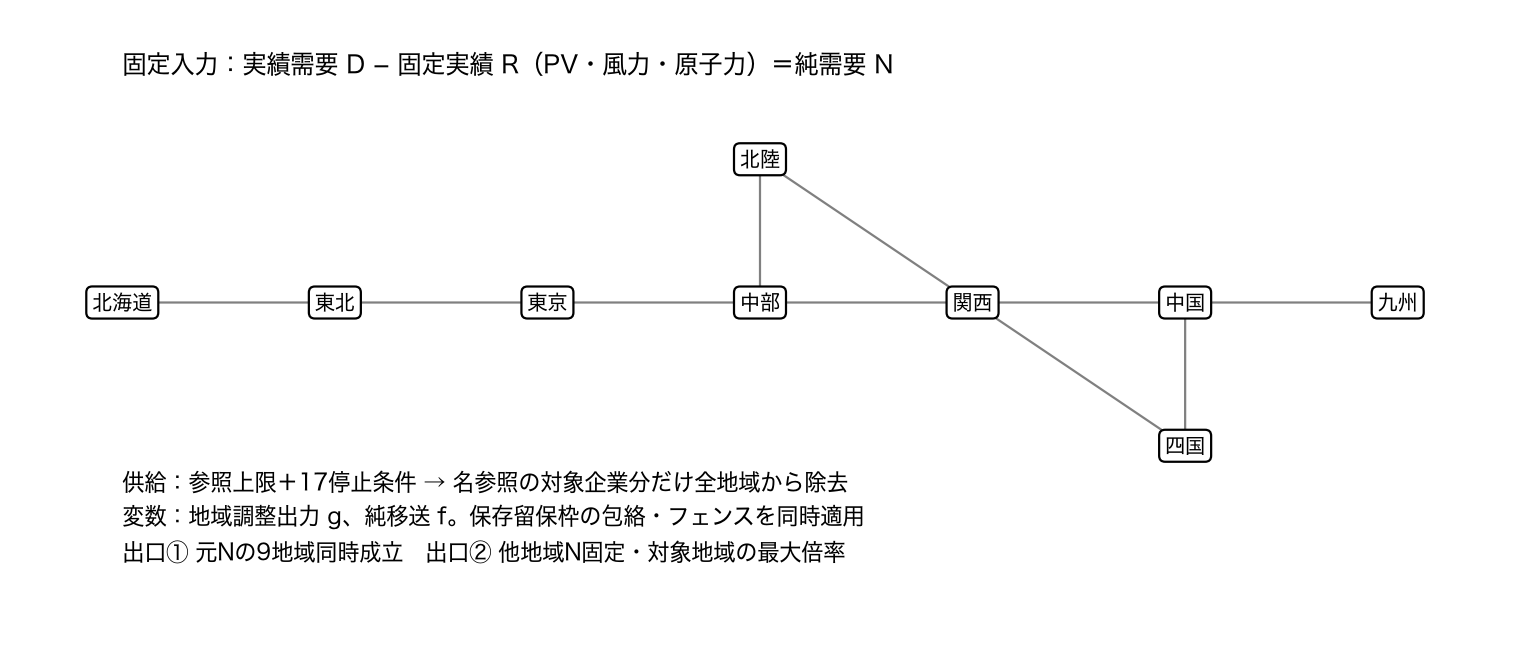

In [2]:
display(Image(filename=str(REPORT / "figures/01_model.png")))

## 図2：17条件内の一致・依存（全17,520コマが分母）

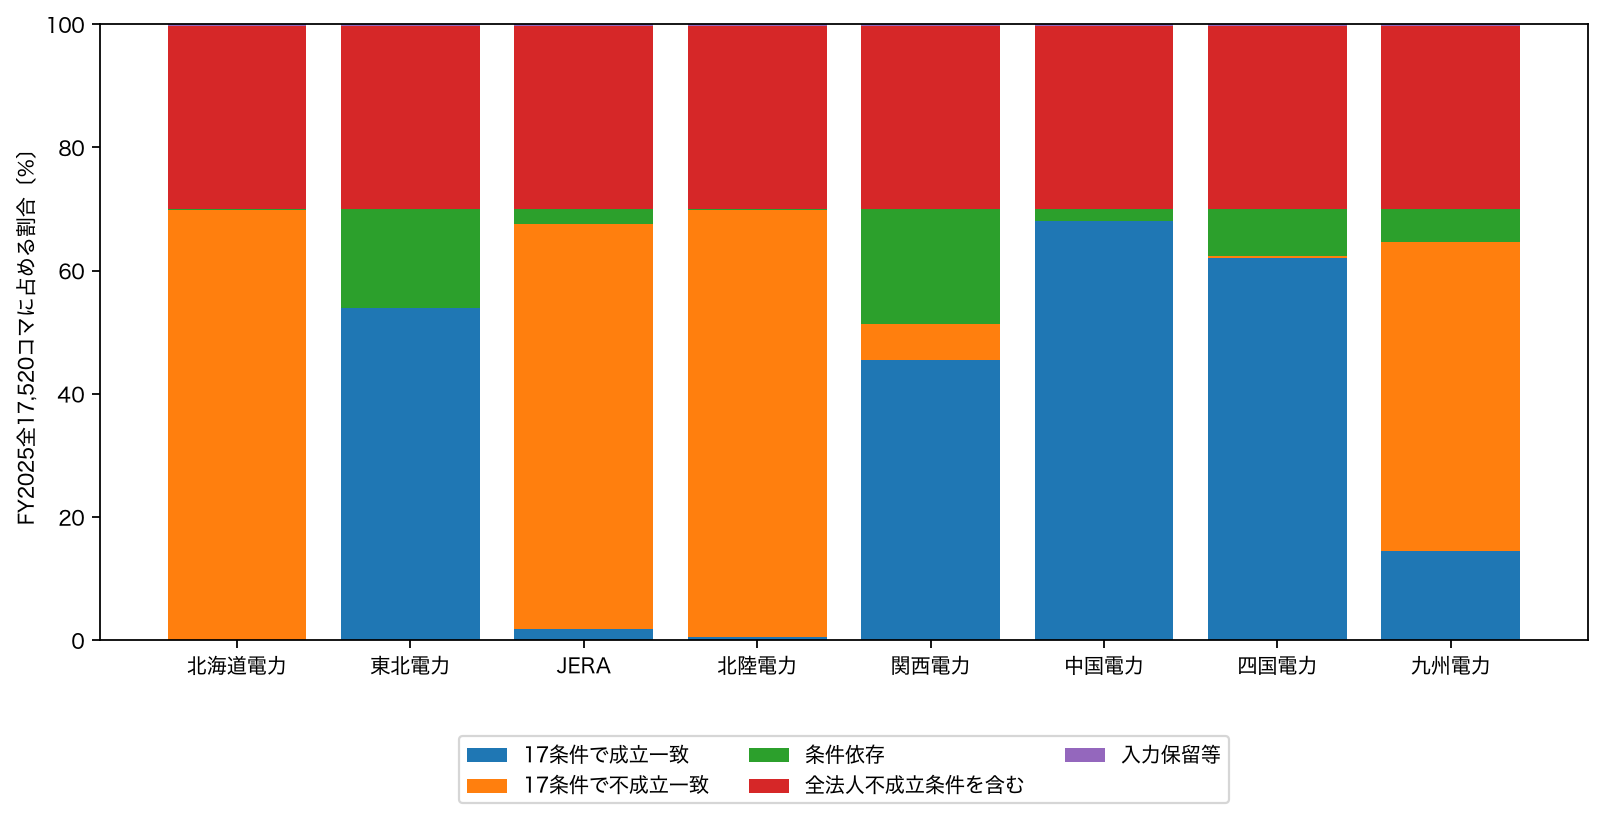

In [3]:
display(Image(filename=str(REPORT / "figures/02_condition_consistency.png")))

## 図3：同一入力・共通16,848コマの送電包絡比較

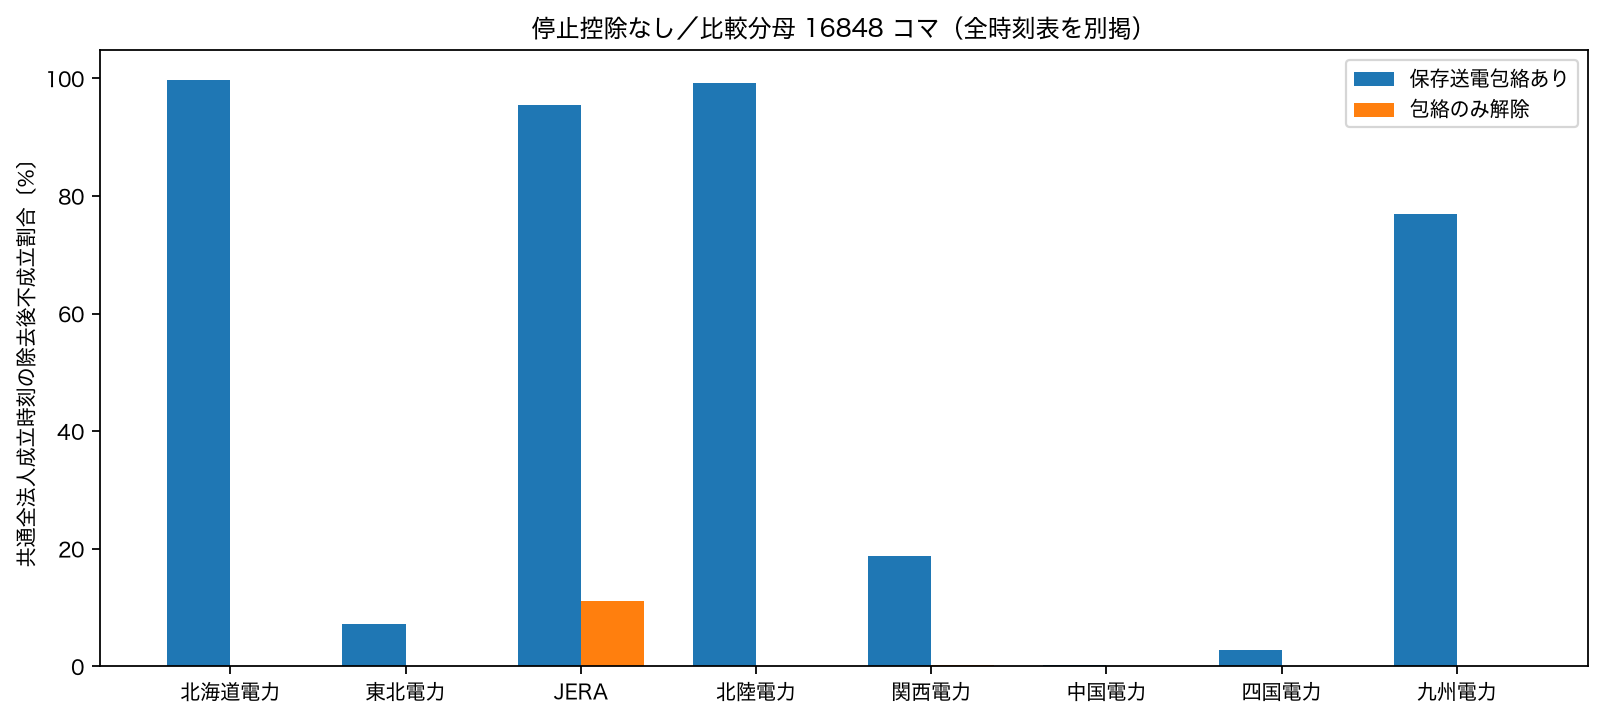

In [4]:
display(Image(filename=str(REPORT / "figures/03_transmission_comparison.png")))

## 図4：倍率と価格（表示0〜2、未算定は状態表へ）

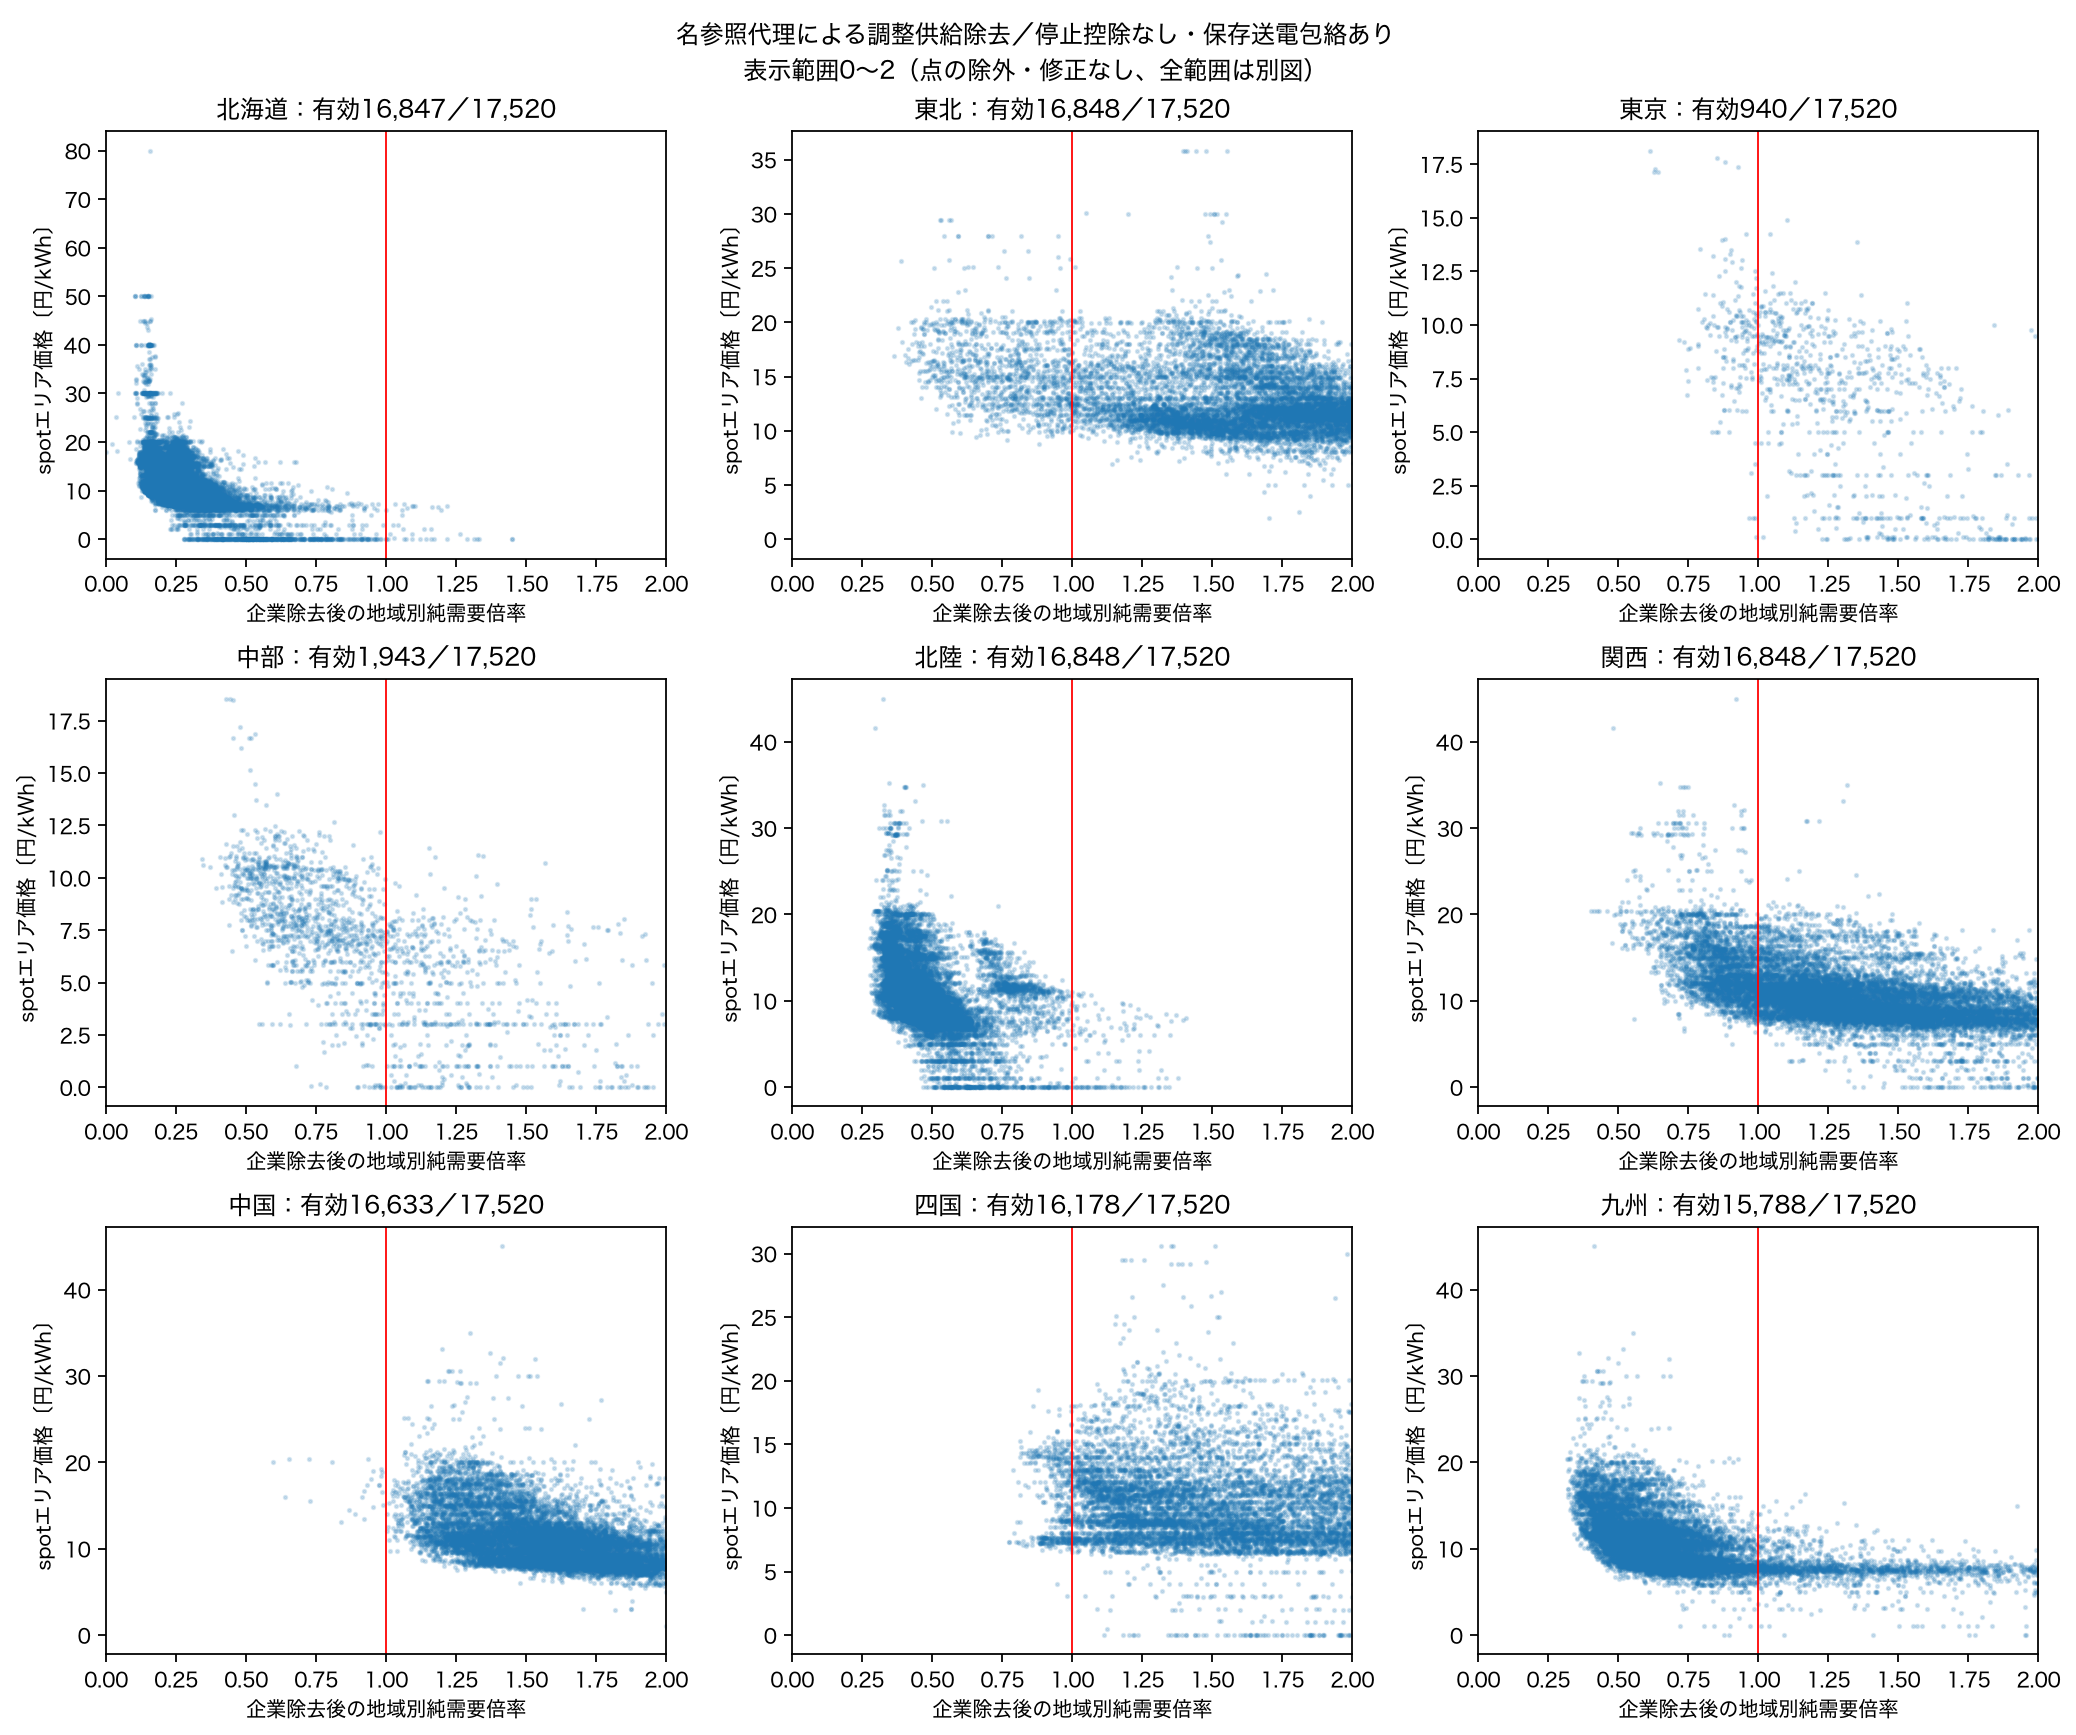

In [5]:
display(Image(filename=str(REPORT / "figures/04_multiplier_price_near_one.png")))

### 教授説明用：東京・中部を除いた7地域（横軸RSI）

既存の地域別純需要倍率を、この表示では **RSI** と略記します。計算定義は変更せず、標準RSIや原TCRSIと同一の定式化を再現したという意味ではありません。

停止控除なし・保存送電包絡あり。東京・中部は**この図の表示対象からのみ**除き、計算は9地域接続のままです。各パネルの `n` は地域ごとの全有効コマ数です（表示範囲外を含む）。横軸は添付図に合わせ0〜2、縦軸は地域ごとの全価格範囲を表示します。全範囲図・全status表は後続セルに保持しています。

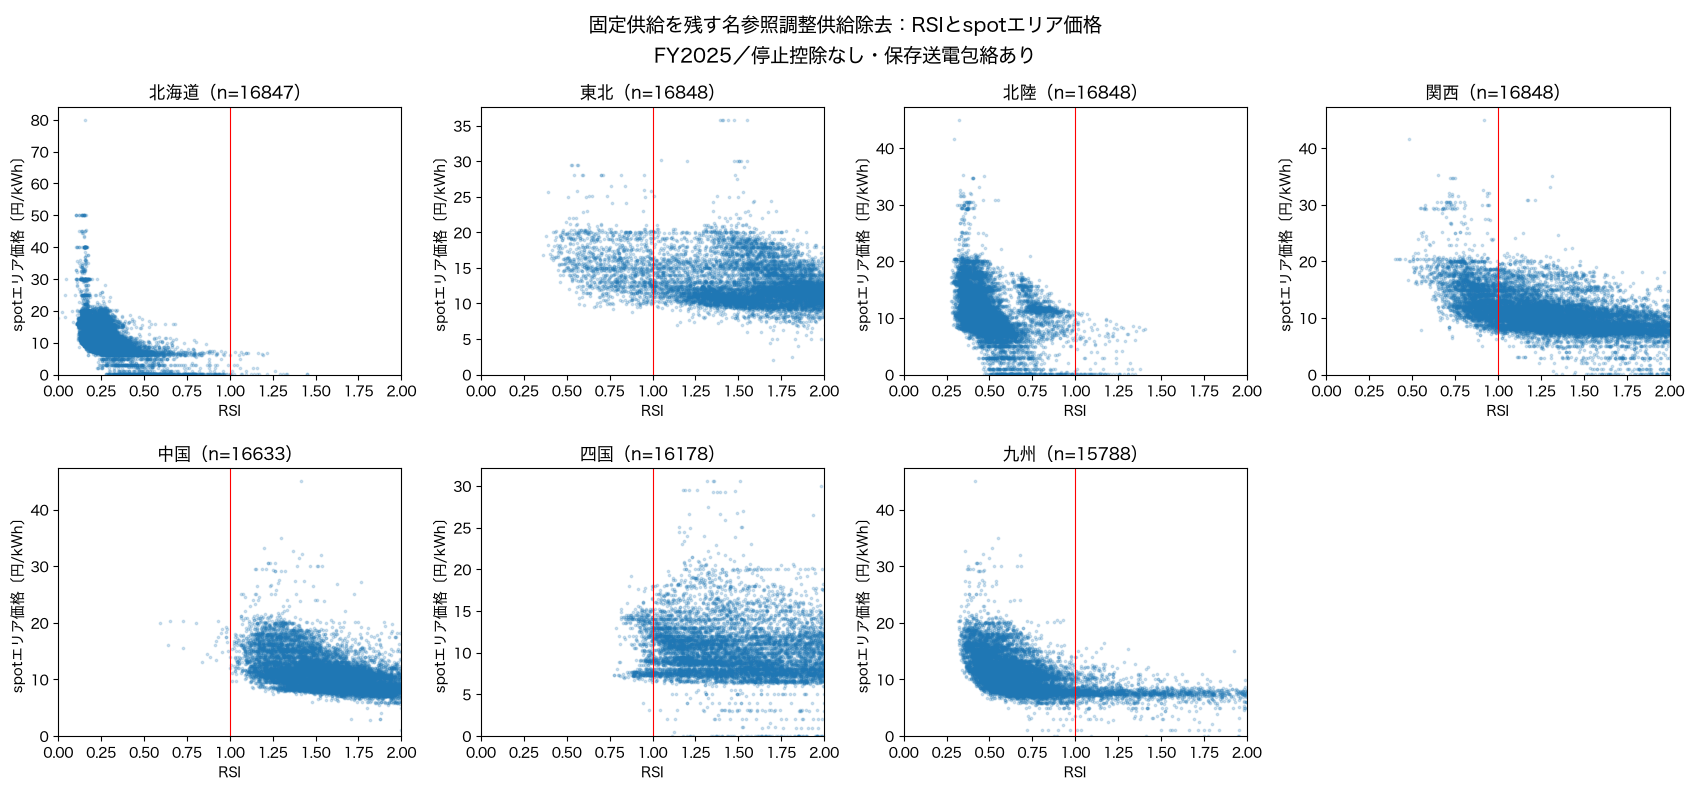

In [ ]:
# 教授説明用の追加表示。既存図・固定データを変更せず、新しいLPは実行しない。
import matplotlib.pyplot as plt
from matplotlib import font_manager

professor_rsi_source = pd.read_parquet(
    DATA / "explanatory_no_stop_priced.parquet",
    columns=["target_area", "network_scenario", "status", "lambda_removed", "area_price"],
)
professor_rsi_areas = ["北海道", "東北", "北陸", "関西", "中国", "四国", "九州"]
professor_rsi_valid = professor_rsi_source[
    professor_rsi_source.network_scenario.eq("saved_plan_constraints")
    & professor_rsi_source.status.eq("valid")
    & professor_rsi_source.target_area.isin(professor_rsi_areas)
].copy()
assert professor_rsi_valid[["lambda_removed", "area_price"]].notna().all().all()
professor_rsi_fonts = [
    font.name for font in font_manager.fontManager.ttflist
    if font.name in ["Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "Arial Unicode MS"]
]
with plt.rc_context({
    "font.family": professor_rsi_fonts[:1] + ["DejaVu Sans"],
    "axes.unicode_minus": False,
}):
    professor_rsi_figure, professor_rsi_panels = plt.subplots(2, 4, figsize=(17, 8))
    for professor_rsi_panel, professor_rsi_area in zip(
        professor_rsi_panels.flat, professor_rsi_areas
    ):
        professor_rsi_points = professor_rsi_valid[
            professor_rsi_valid.target_area.eq(professor_rsi_area)
        ]
        professor_rsi_panel.scatter(
            professor_rsi_points.lambda_removed,
            professor_rsi_points.area_price.astype(float),
            s=3, alpha=0.2, rasterized=True,
        )
        professor_rsi_panel.axvline(1, color="red", linewidth=0.8)
        professor_rsi_panel.set(
            xlim=(0, 2), xlabel="RSI", ylabel="spotエリア価格〔円/kWh〕",
            title=f"{professor_rsi_area}（n={len(professor_rsi_points)}）",
        )
        professor_rsi_panel.set_ylim(bottom=0)
    professor_rsi_panels.flat[-1].set_visible(False)
    professor_rsi_figure.suptitle(
        "固定供給を残す名参照調整供給除去：RSIとspotエリア価格\n"
        "FY2025／停止控除なし・保存送電包絡あり", fontsize=14,
    )
    professor_rsi_figure.tight_layout(rect=[0, 0, 1, 1], h_pad=2, w_pad=1.5)
    plt.show()


### 教授への説明：RSIは「必要な量の何倍まで、他者で届けられるか」

$$
\boxed{\displaystyle
\mathrm{RSI}_{i,r,t}
=\frac{\text{対象企業を除いた他者が、その地域へ供給できる最大量〔MW〕}}
{\text{その地域の純需要〔MW〕}}
=\frac{Q^{\max}_{-i,r,t}}{D_{r,t}-R_{r,t}}
}
$$

**純需要＝実績需要 − PV・風力・原子力の実績**です。これらの固定供給は、対象企業のものであっても残します。

- **分子**は、域内の他者の調整供給と域外からの純輸入を合わせて、対象地域で満たせる最大量です。他地域も自分の純需要を満たし、送電制約を守る条件で求めます。他地域の設備容量をそのまま足した値ではありません。
- **分母**は固定供給で満たした後に残る、対象地域の元の純需要です。対象企業の実績発電量をさらに引きません。
- 例えば純需要100MWに対して最大150MWまで届けられれば **RSI=1.5**、最大80MWなら **RSI=0.8**。この数値例は説明用です。比率を計算できない時刻は0にしていません。

本図のRSIは、既存の**地域別純需要倍率**の略記です。元需要の成立は別の検査でも確認します。厳密な定式化は次のセルへ残しています。

**先行研究の該当箇所**：Lee・Baldick・Hur（2011）の[IEEE掲載版・著者公開PDF](https://www.researchgate.net/profile/R-Baldick/publication/224241936_Firm-Based_Measurements_of_Market_Power_in_Transmission-Constrained_Electricity_Markets/links/0deec52b318baaa94b000000/Firm-Based-Measurements-of-Market-Power-in-Transmission-Constrained-Electricity-Markets.pdf)では、基本RSIの比率は **p.1965・§III冒頭（式番号なし）**、TCRSIの最大化問題は **pp.1966–1967・式(7a)〜(7e)**、TCRSIの定義は **p.1967・Definition 1** です。同著者のTechnical Reference版では **p.16・式(14a)〜(14e)** に対応します。

原論文は全母線需要を同じ倍率で動かすPTDFモデルです。今回は**対象地域のみの倍率、固定実績R、調整供給だけの名参照除去、9地域輸送、保存資料の送電上限**へ変更しています。根拠のない独自指数ではありませんが、原TCRSIそのものの再現とも区別します。

### 横軸の計算式（本図でRSIと略記する地域別純需要倍率）

対象企業を $i$、評価地域を $r$、時刻を $t$ とします。既存の計算は次の最大化問題です。

$$
\mathrm{RSI}_{i,r,t}\equiv\lambda^{\max}_{i,r,t}
=\max_{\lambda,\,g,\,f}\ \lambda
$$

$$
\begin{aligned}
 g_a+(Af)_a&=
 \begin{cases}
 \lambda N_{r,t}, & a=r,\\
 N_{a,t}, & a\ne r,
 \end{cases}
 &&\forall a\in\mathcal A,\\
 0\le g_a&\le V^{-i}_{a,t}
 =\sum_{j\in J_{a,t}}(1-I_{ij})\,U_{j,t},
 &&\forall a\in\mathcal A,\\
 L_{k,t}&\le (C_t f)_k\le H_{k,t},
 &&\forall k,\\
 \lambda&\ge0,\qquad N_{r,t}>0.
\end{aligned}
$$

$$
N_{a,t}=D_{a,t}-R_{a,t},\qquad
R_{a,t}=G^{\mathrm{PV}}_{a,t}+G^{\mathrm{wind}}_{a,t}+G^{\mathrm{nuclear}}_{a,t}.
$$

- $D$：公表実績需要、$R$：分析上固定するPV・風力・原子力の地域実績。対象企業分であっても $R$ は残します。
- $J_{a,t}$：既存の限定設備集合のうち参照上限を数値として使える調整設備。$I_{ij}=1$ はHJKS名参照代理で対象企業 $i$ に対応する設備で、**モデル内の全地域から**同時に除きます。
- $U_{j,t}$：本図は停止控除なしの参照上限。元kWを1,000で除したMWです。実績発電量を追加で引きません。$V^{-i}$ は除去後に残る既知上限の部分和です。
- $g_a$：地域の調整出力、$f$：区間の純移送、$A$：受電を正とする接続行列。$C_t$ と $L,H$：対象時刻の区間・フェンスの係数と保存上下限。これらの数量はMW、RSIは無次元です。
- **読み方**：RSI=1.5なら、他地域の元の純需要を保ったまま評価地域の純需要を最大1.5倍まで満たす割当てがある、という意味です。固定 $R$ は倍率を掛けません。
- 純需要非正・全法人不成立・倍率問題不成立・入力保留等を0に置換していません。元需要が成立するかは独立した検査で確認し、最大倍率が1以上という条件だけへ置換しません。標準RSIの単純な容量／需要比、原TCRSIの全地域共通倍率、企業行動・価格効果の推定とは区別します。


## 付録：倍率と価格の全範囲

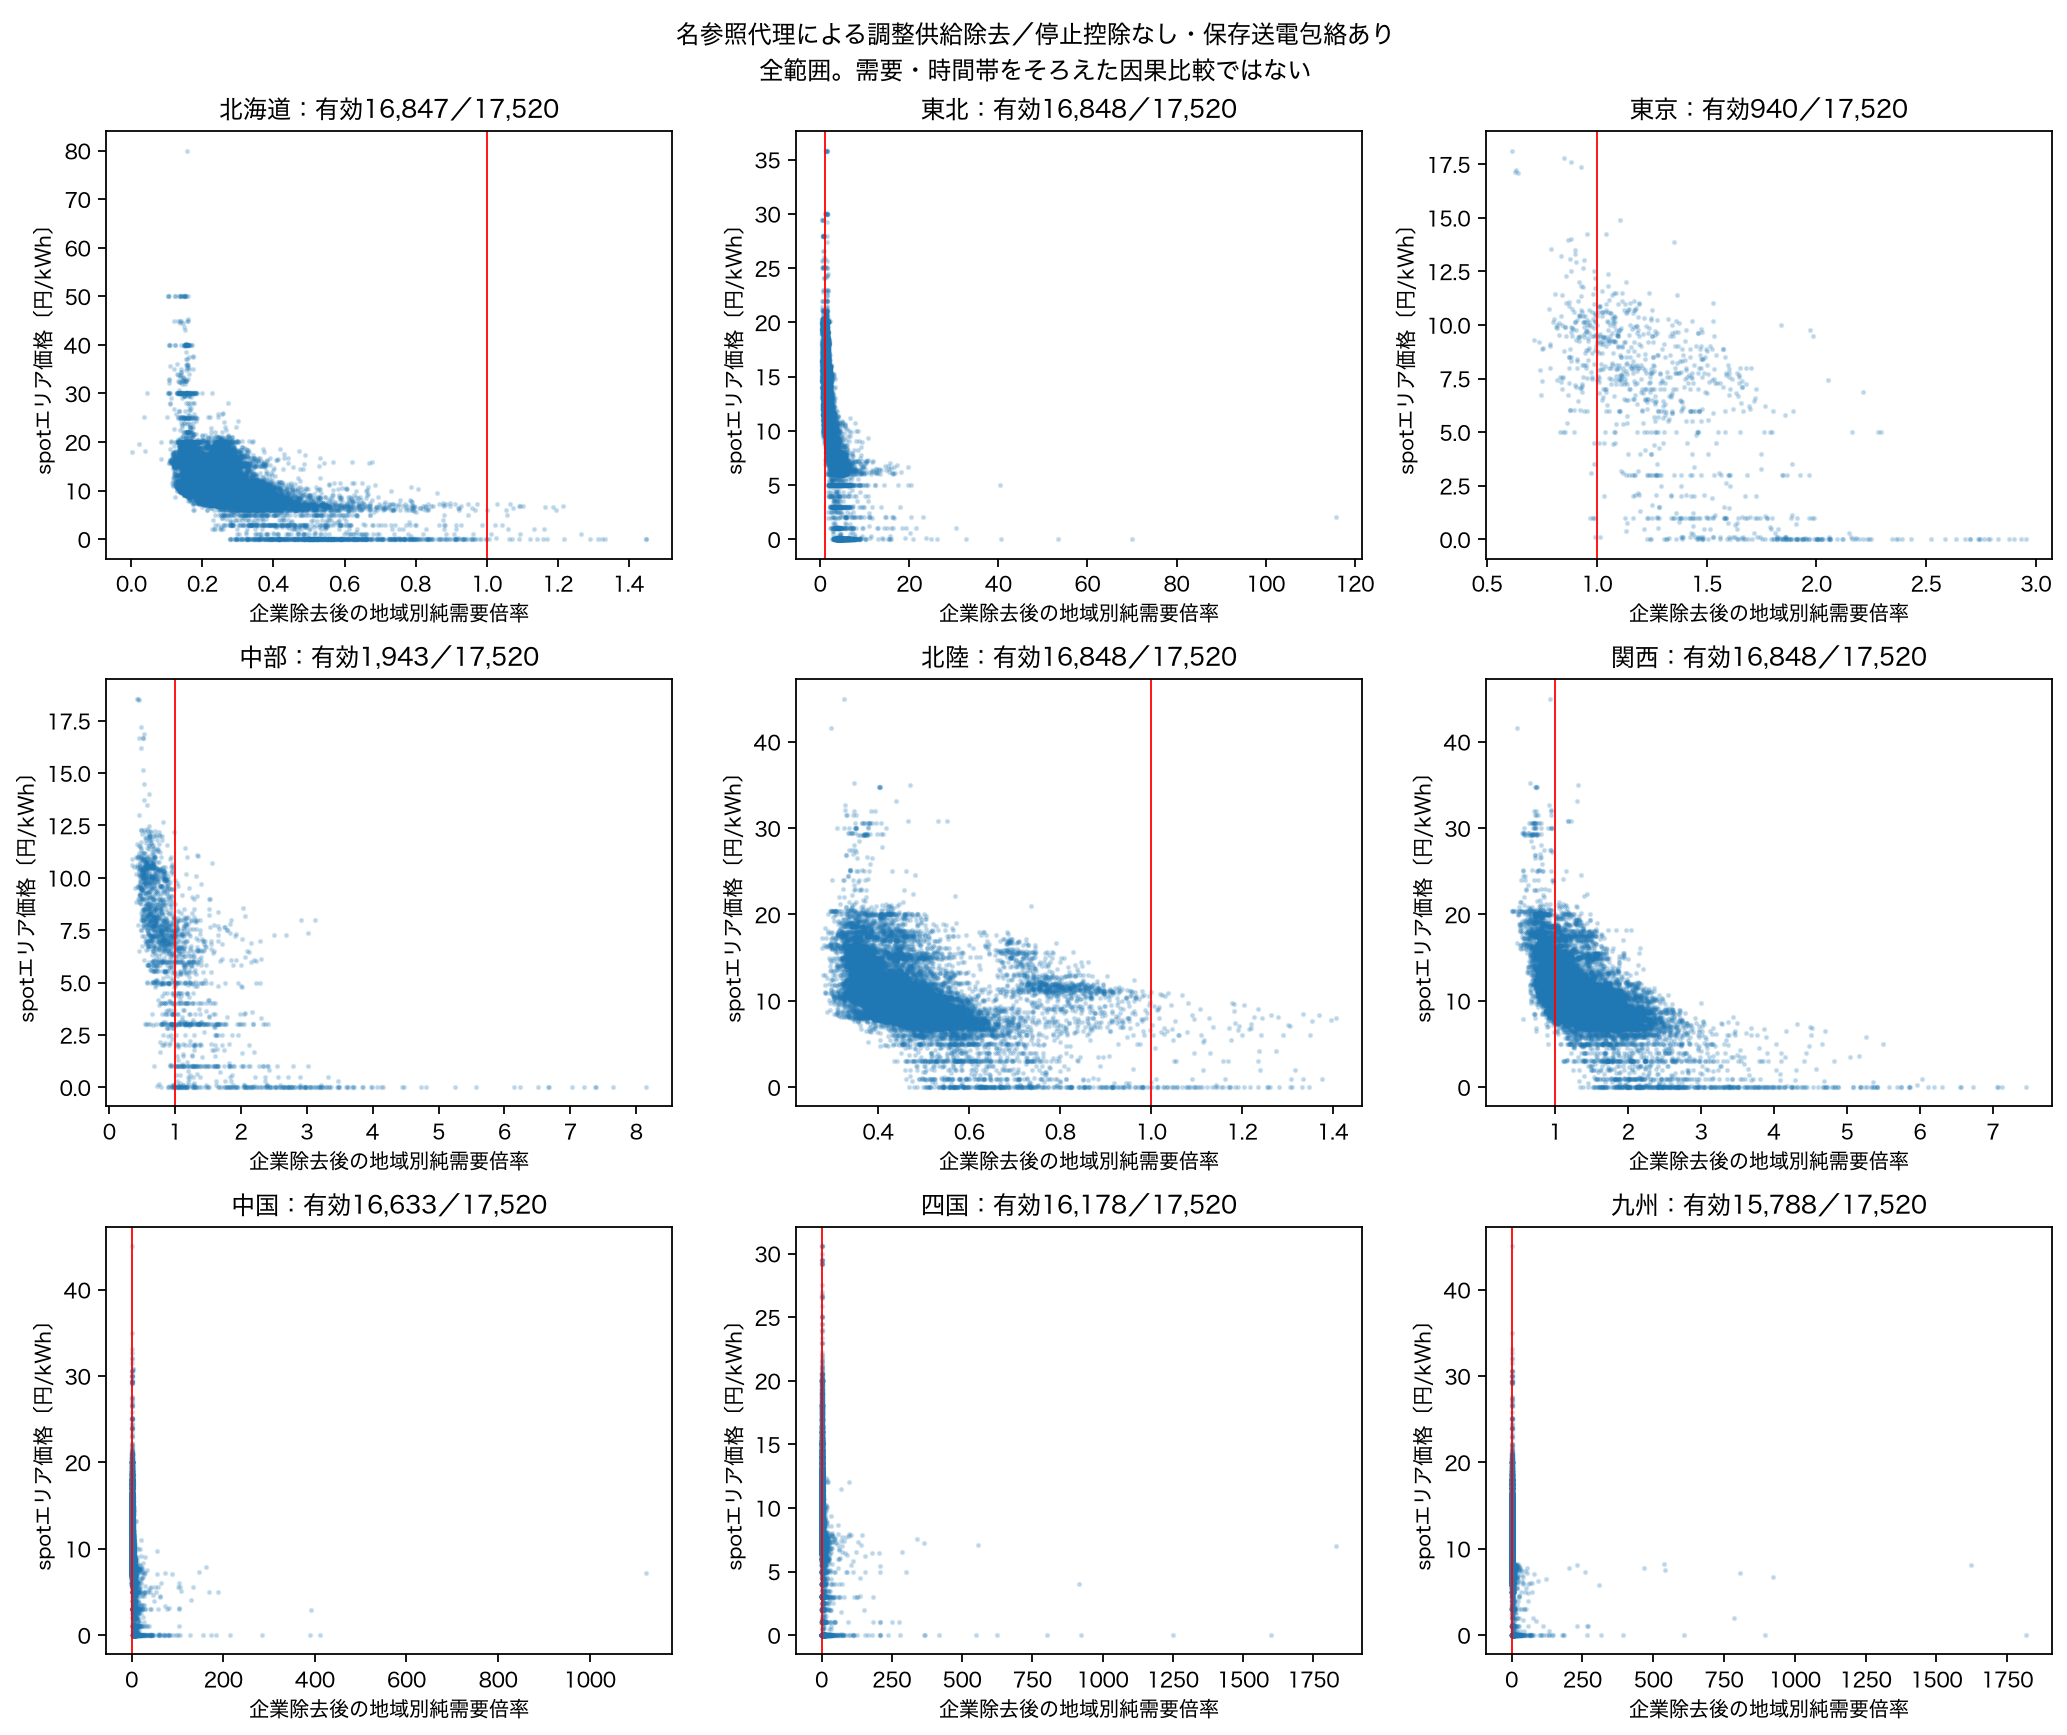

In [6]:
display(Image(filename=str(REPORT / "figures/04_multiplier_price_full.png")))

Matplotlib is building the font cache; this may take a moment.


### 全地域で軸を揃えた比較表示（横軸0〜10・縦軸0〜25）

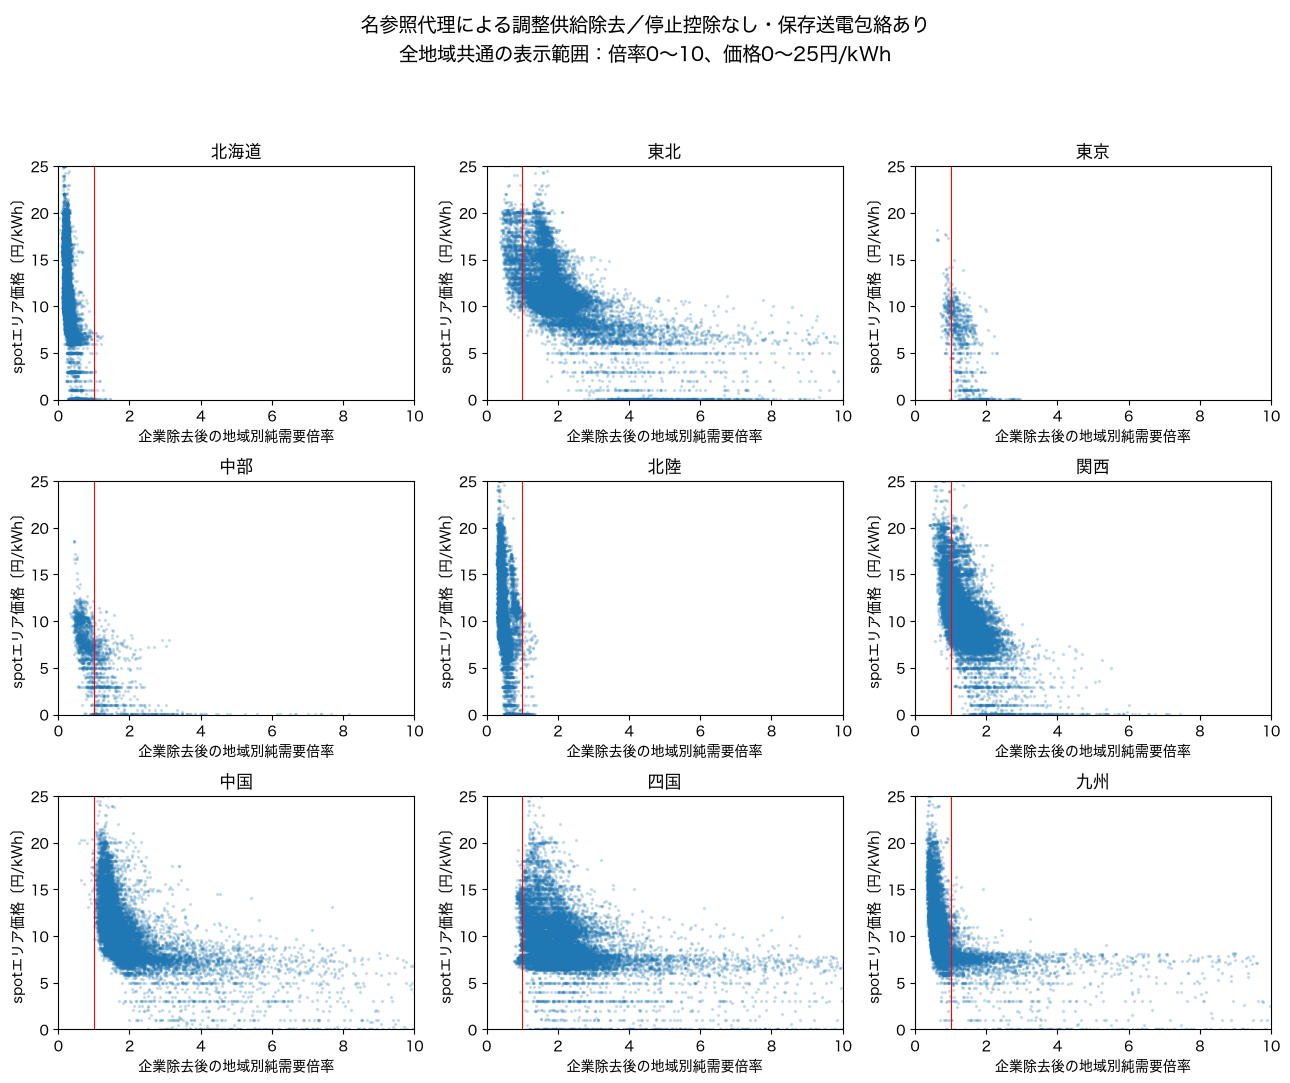

In [2]:
# 比較用の表示範囲だけを統一。元データと直上の全範囲図は変更しない。
import matplotlib.pyplot as plt
from matplotlib import font_manager

common_axis_fonts = [
    font.name
    for font in font_manager.fontManager.ttflist
    if font.name in ["Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "Arial Unicode MS"]
]
common_axis_source = pd.read_parquet(
    DATA / "explanatory_no_stop_priced.parquet",
    columns=["target_area", "network_scenario", "status", "lambda_removed", "area_price"],
)
common_axis_valid = common_axis_source[
    common_axis_source.network_scenario.eq("saved_plan_constraints")
    & common_axis_source.status.eq("valid")
]
common_axis_areas = ["北海道", "東北", "東京", "中部", "北陸", "関西", "中国", "四国", "九州"]
display(Markdown("### 全地域で軸を揃えた比較表示（横軸0〜10・縦軸0〜25）"))
with plt.rc_context(
    {
        "font.family": common_axis_fonts[:1] + ["DejaVu Sans"],
        "axes.unicode_minus": False,
    }
):
    common_axis_figure, common_axis_panels = plt.subplots(
        3, 3, figsize=(13, 11), sharex=True, sharey=True
    )
    for common_axis_panel, common_axis_area in zip(common_axis_panels.flat, common_axis_areas):
        common_axis_points = common_axis_valid[common_axis_valid.target_area.eq(common_axis_area)]
        common_axis_panel.scatter(
            common_axis_points.lambda_removed,
            common_axis_points.area_price.astype(float),
            s=2,
            alpha=0.18,
            rasterized=True,
        )
        common_axis_panel.axvline(1, color="red", linewidth=0.8)
        common_axis_panel.set(
            xlim=(0, 10),
            ylim=(0, 25),
            xticks=[0, 2, 4, 6, 8, 10],
            yticks=[0, 5, 10, 15, 20, 25],
            title=common_axis_area,
            xlabel="企業除去後の地域別純需要倍率",
            ylabel="spotエリア価格〔円/kWh〕",
        )
        common_axis_panel.tick_params(labelbottom=True, labelleft=True)
    common_axis_figure.suptitle(
        "名参照代理による調整供給除去／停止控除なし・保存送電包絡あり\n"
        "全地域共通の表示範囲：倍率0〜10、価格0〜25円/kWh",
        fontsize=14,
    )
    common_axis_figure.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

## 付録：季節差と算定範囲を同時に確認

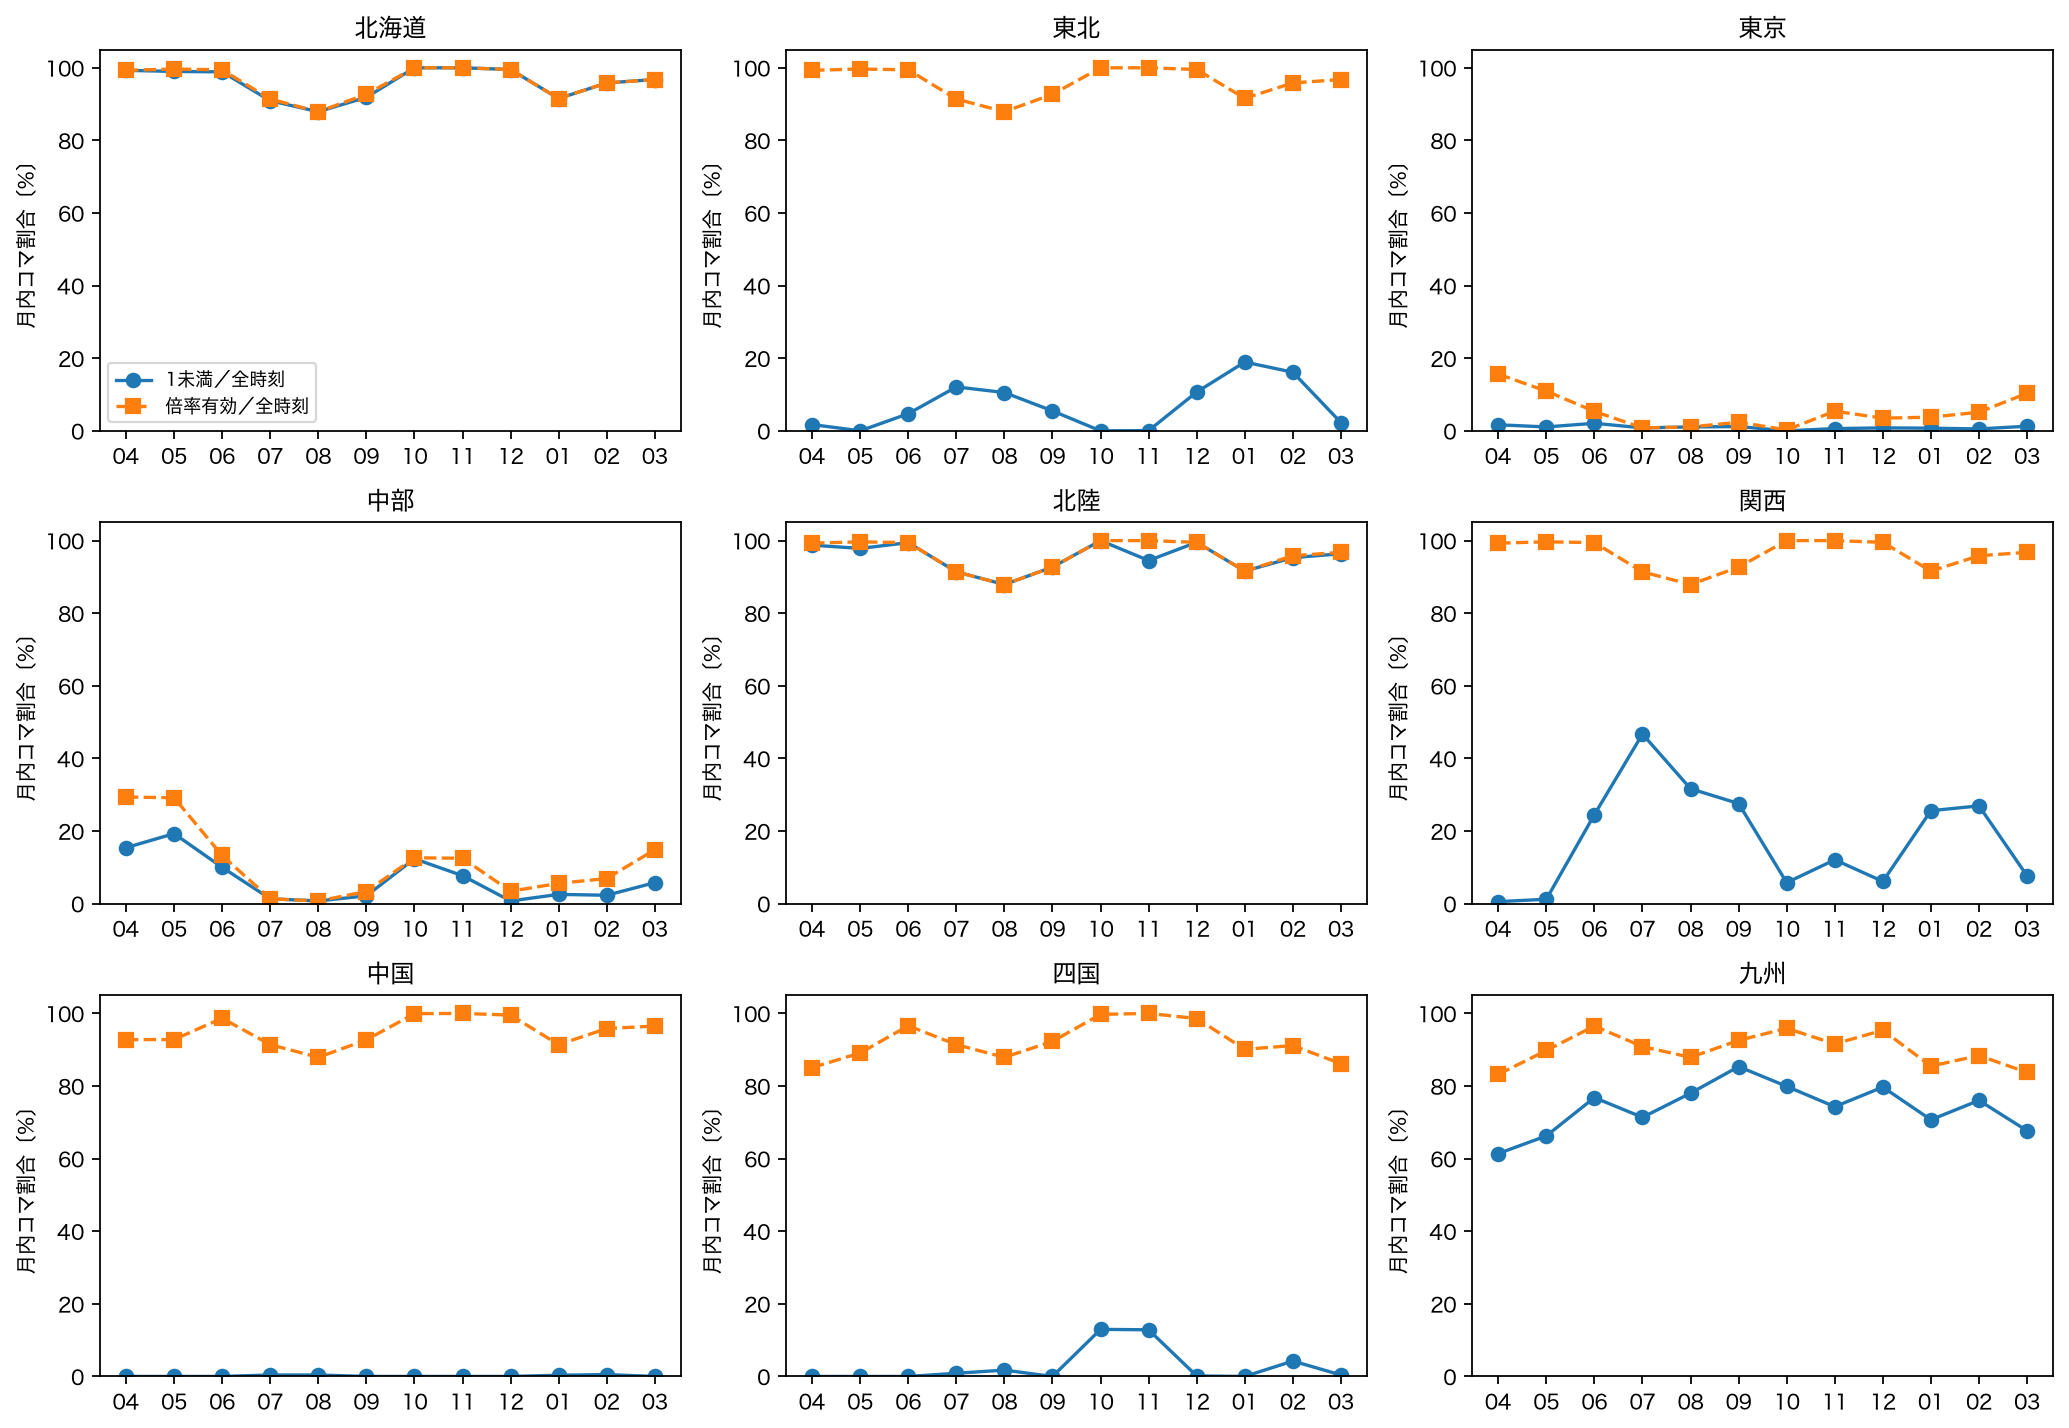

In [7]:
display(Image(filename=str(REPORT / "figures/A01_monthly_status.png")))

## 全時刻・月別・仮定を確認

倍率の有効時刻だけが全体ではありません。以下には全status・保留と比較分母も含みます。
JERAの同時成立は1法人、倍率/価格は東京・中部の別評価です。
同じ価格を34条件に反復した枠を、独立観測として合計しません。

In [8]:
for file in [
    "explanatory_annual.csv",
    "transmission_common_times.csv",
    "condition_consistency_annual.csv",
    "explanatory_monthly.csv",
    "table1_data_definitions.csv",
    "table2_assumptions.csv",
]:
    display(Markdown("### " + file))
    display(pd.read_csv(QA / file))

### explanatory_annual.csv

,network_scenario,target_area,frames,valid,below_one,lambda_median,lambda_min,lambda_max,all_firms_infeasible,nonpositive,other_infeasible,held
0,no_transmission_bounds,中国,17520,17287,119,11.299610,0.037765,14767.138571,5,228,0,0
1,no_transmission_bounds,中部,17520,17054,2004,2.849717,0.000099,102.077627,5,0,461,0
2,no_transmission_bounds,九州,17520,16435,188,10.221078,0.015776,36916.485000,5,1080,0,0
3,no_transmission_bounds,北海道,17520,17511,42,20.932201,0.018772,255.440784,5,0,4,0
4,no_transmission_bounds,北陸,17520,17514,38,19.880896,0.109864,137.713601,5,0,1,0
5,no_transmission_bounds,四国,17520,16830,16,31.932925,0.238031,50388.485000,5,685,0,0
6,no_transmission_bounds,東京,17520,17515,2465,1.821140,0.279085,13.207306,5,0,0,0
7,no_transmission_bounds,東北,17520,17515,91,8.777858,0.335257,856.203426,5,0,0,0
8,no_transmission_bounds,関西,17520,17515,382,5.822973,0.255375,68.143113,5,0,0,0
9,saved_plan_constraints,中国,17520,16633,24,1.681639,0.594313,1123.675714,611,228,0,48


### transmission_common_times.csv

,entity_code,denominator,excluded,constrained_infeasible,unconstrained_infeasible
0,hokkaido,16848,672,16811,0
1,tohoku,16848,672,1202,0
2,jera,16848,672,16081,1861
3,hokuriku,16848,672,16721,0
4,kansai,16848,672,3150,33
5,chugoku,16848,672,24,0
6,shikoku,16848,672,482,0
7,kyushu,16848,672,12954,1


### condition_consistency_annual.csv

...

,network_scenario,target_area,month,frames,valid,below_one,lambda_min,lambda_median,lambda_max,price_median_all,price_median_valid
0,no_transmission_bounds,中国,202504,1440,1338,0,4.627773,15.926890,14767.138571,10.450,10.565
1,no_transmission_bounds,中国,202505,1488,1381,0,7.239946,17.974388,4546.103684,8.150,8.400
2,no_transmission_bounds,中国,202506,1440,1429,0,2.534488,14.556178,585.792722,8.430,8.490
3,no_transmission_bounds,中国,202507,1488,1488,7,0.653320,10.381485,69.071598,10.310,10.310
4,no_transmission_bounds,中国,202508,1488,1483,44,0.037765,9.681534,61.432600,9.670,9.650
...,...,...,...,...,...,...,...,...,...,...,...
211,saved_plan_constraints,関西,202511,1440,1440,174,0.737704,1.413226,4.716596,9.390,9.390
212,saved_plan_constraints,関西,202512,1488,1481,91,0.744656,1.434841,3.614259,9.600,9.600
213,saved_plan_constraints,関西,202601,1488,1363,381,0.477904,1.181365,4.701011,9.920,9.660
214,saved_plan_constraints,関西,202602,1344,1288,362,0.524982,1.169089,6.026112,10.000,9.890


### table1_data_definitions.csv

,symbol,definition_ja,unit_grain,scope_qa,source
0,D,同じ燃料別CSVの公表実績需要,MW平均・地域×30分,"9地域17,520時刻。入力欠測0",公式一次CSV108地域月（新規88CSV＋保有8CSV＋保有年度ZIP12CSV）
1,R,分析上固定するPV・風力・原子力実績の和,MW平均・地域×30分,Dと同じCSV・同じ区間。制御量を加算しない,同上。原列と資料別契約を保持
2,N,D−R,MW・地域×30分,非正も保存。通常倍率だけ保留,annual_primary_input_ledger.parquet
3,U,調整候補の参照上限・既存17停止条件,元kW／1000→MW,374ラベル候補・数値定義部分の和。未知全容量の分母なし,既存677台帳・Issue40年間unit表・工程25の2設備根拠
4,企業代理,HJKS発電事業者名の除去代理,8法人・9地域法人対,所有・支配・契約と別。EP/ミライズ未評価,工程21全491設備代理表。地理による追加なし
5,送電B,原符号C−M−Wとフェンス係数,MW・区間/フェンス×30分,"17,472定義／48保留。保存留保枠を維持",保存翌々日CSV・公式切替資料（仕様書のページ参照）
6,価格,spotのエリア価格・実績system price,円/kWh・地域×30分,"157,680地域時刻。全結果枠join100%",既存JEPX spot。感応度基準は別列
7,REI,一次実績との検算,MW・地域×30分,原本の明示ヘッダーで地域を選択,補助資料。一次値を置換しない


### table2_assumptions.csv

,assumption,adopted_diagnostic_specification,observed_impact,interpretation_limit
0,限定設備・容量一定,374調整候補＋固定R、既知部分だけ,17条件の保留数と既知上限を併記,不成立は実系統の不足・企業不可欠性ではない
1,北海道2設備,室蘭100MW、釧路112MWを含む同一版,旧4月と新年間4月の全status一致。旧集合の年間再計算なし,卸供給・発電端・送電端/契約は統一済みでない。釧路100MWへ無断置換しない
2,停止不明の扱い,元8条件と追加控除なし8比較,"例：58,852早端・全停止0で関西の共通有効12,929中1,420が1未満→1超へ",参照値へ戻すことは利用可能性の確認ではない
3,停止0／平均低下量,既存2方式を保持,全法人時の既知部分和が同じ条件も0/null・保留量が異なる,公表平均を時点損失と確認したわけではない
4,保存送電B,C−M−Wを総純移送の包絡に使用,"共通16,848時刻：JERA不成立16,081→包絡解除1,861",保留枠再設計・実混雑/増強効果の推計ではない
5,年度末表示切替,新3フェンスが揃う864時刻を別契約で使用,3/13の48は保留。旧中央3区間は重ねない,実物理切替の完了時刻は推定しない
6,公表需要のみ,観測充電の再現を要求しない,全国既知上限不足5時刻、送達/局所吸収等619時刻（控除なし）,総充電を復元しない。吸収先不足が残り得る
7,価格比較,説明用条件を固定、全status・月別を併記,"北海道1超36時刻の価格中央値1.005円、1未満16,810時刻10.93円",需要・季節・時間帯をそろえた因果効果や行使の証拠ではない


## 実データを見る

説明用条件だけの表を読み、最初の10行を示します。データ全体の価格・元値は保存されたままです。
全17条件は `priced_multipliers/` の月×条件ファイル、同時成立は別の `results_v1/simultaneous/`。
送電切替日の48コマは送電ありで保留、包絡なしは計算可能です。

In [9]:
data = pd.read_parquet(DATA / "explanatory_no_stop_priced.parquet")
display(pd.DataFrame({"列名": data.columns, "型": [str(t) for t in data.dtypes]}))
display(data.head(10))
display(
    data.groupby(["network_scenario", "target_area", "status"])
    .size()
    .rename("コマ数")
    .reset_index()
)
display(pd.read_csv(QA / "output_column_dictionary.csv").head(25))

,列名,型
0,supply_trial_scenario,str
1,network_scenario,str
2,delivery_date,object
3,period,int64
4,target_area,str
5,entity_code,str
6,entity,str
7,status,str
8,lambda_all_firms,float64
9,lambda_removed,float64


,supply_trial_scenario,network_scenario,delivery_date,period,target_area,entity_code,entity,status,lambda_all_firms,lambda_removed,...,removed_simultaneous_status,target_net_demand_mw,held_candidate_cells,removed_adjustable_mw_all_nine_areas,removed_fixed_output_mw,month,area_price,system_price_market,system_price_sensitivity_base,baseline_price_match_flag
0,reference_no_deduction,saved_plan_constraints,2025-04-01,1,北海道,hokkaido,北海道電力株式会社,valid,1.946006,0.227910,...,infeasible,3067.0,1,5269.4,0.0,202504,15.41,13.50,13.50,True
1,reference_no_deduction,saved_plan_constraints,2025-04-01,1,東北,tohoku,東北電力株式会社,valid,2.695042,1.683015,...,feasible,7483.0,1,7573.0,0.0,202504,15.41,13.50,13.50,True
2,reference_no_deduction,saved_plan_constraints,2025-04-01,1,東京,jera,株式会社JERA,removed_other_regions_infeasible,1.436335,NaN,...,infeasible,28718.0,1,36340.9,0.0,202504,15.41,13.50,13.50,True
3,reference_no_deduction,saved_plan_constraints,2025-04-01,1,中部,jera,株式会社JERA,removed_other_regions_infeasible,1.695304,NaN,...,infeasible,13160.0,1,36340.9,0.0,202504,11.00,13.50,13.50,True
4,reference_no_deduction,saved_plan_constraints,2025-04-01,1,北陸,hokuriku,北陸電力株式会社,valid,2.027981,0.391807,...,infeasible,3027.0,1,4952.7,0.0,202504,11.00,13.50,13.50,True
5,reference_no_deduction,saved_plan_constraints,2025-04-01,1,関西,kansai,関西電力株式会社,valid,3.307243,1.434140,...,feasible,8566.0,1,16427.0,0.0,202504,11.00,13.50,13.50,True
6,reference_no_deduction,saved_plan_constraints,2025-04-01,1,中国,chugoku,中国電力株式会社,valid,2.968254,1.346146,...,feasible,5229.0,1,8482.0,0.0,202504,11.00,13.50,13.50,True
7,reference_no_deduction,saved_plan_constraints,2025-04-01,1,四国,shikoku,四国電力株式会社,valid,3.860072,1.507841,...,feasible,1658.0,1,3900.0,0.0,202504,7.81,13.50,13.50,True
8,reference_no_deduction,saved_plan_constraints,2025-04-01,1,九州,kyushu,九州電力株式会社,valid,2.385926,0.641917,...,infeasible,5926.0,1,10335.0,0.0,202504,11.00,13.50,13.50,True
9,reference_no_deduction,no_transmission_bounds,2025-04-01,1,北海道,hokkaido,北海道電力株式会社,valid,20.175406,18.457310,...,feasible,3067.0,1,5269.4,0.0,202504,15.41,13.50,13.50,True


,network_scenario,target_area,status,コマ数
0,no_transmission_bounds,中国,all_firms_infeasible,5
1,no_transmission_bounds,中国,nonpositive_target_net,228
2,no_transmission_bounds,中国,valid,17287
3,no_transmission_bounds,中部,all_firms_infeasible,5
4,no_transmission_bounds,中部,removed_other_regions_infeasible,461
5,no_transmission_bounds,中部,valid,17054
6,no_transmission_bounds,九州,all_firms_infeasible,5
7,no_transmission_bounds,九州,nonpositive_target_net,1080
8,no_transmission_bounds,九州,valid,16435
9,no_transmission_bounds,北海道,all_firms_infeasible,5


,table_group,column_name,type,definition_ja,unit,example_file,limitation
0,primary,DATE,large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
1,primary,TIME,large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
2,primary,エリア需要,large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
3,primary,原子力,large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
4,primary,火力(LNG),large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
5,primary,火力(石炭),large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
6,primary,火力(石油),large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
7,primary,火力(その他),large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
8,primary,火力出力制御量,large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
9,primary,水力,large_string,元列/出典識別子または診断補助列。元表の定義と文脈を保持,not_applicable,data/interim/occto/annual_diagnostic/20261027_...,限定集合/固定R/保存留保枠/名参照。確認済み利用可能性ではない
